In [1]:
#Importing necessary libraries and dataset
import pandas as pd
import numpy as np
df=pd.read_csv('heart1.csv')
df.head()

,age,sex,cp,trtbps,chol,fbs,restecg,thalachh,exng,oldpeak,slp,caa,thall,output
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [2]:
#Checking missing values
df.isnull().sum()

age         0
sex         0
cp          0
trtbps      0
chol        0
fbs         0
restecg     0
thalachh    0
exng        0
oldpeak     0
slp         0
caa         0
thall       0
output      0
dtype: int64

In [3]:
feat=df.drop('output',axis=1)
target=df['output']

In [4]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(feat.values)

In [5]:
#PCA
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(feat.values)


Text(0.5, 1.0, 'Component-wise and Cumulative Explained Variance')

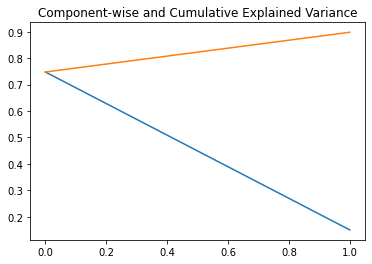

In [6]:
#Plotting
import matplotlib.pyplot as plt
plt.plot(range(2), pca.explained_variance_ratio_)
plt.plot(range(2), np.cumsum(pca.explained_variance_ratio_))
plt.title("Component-wise and Cumulative Explained Variance")

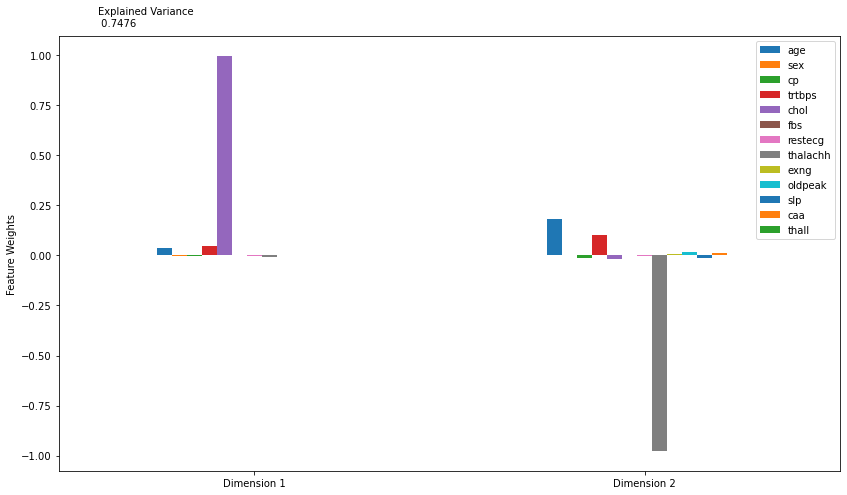

In [10]:
#Visualizing the components:
def pca_results(good_data, pca):
    dimensions=dimensions = ['Dimension {}'.format(i) for i in range(1,len(pca.components_)+1)]
    components=pd.DataFrame(np.round(pca.components_, 4), columns = list(good_data.keys()))
    components.index=dimensions
    ratios = pca.explained_variance_ratio_.reshape(len(pca.components_), 1)
    variance_ratios = pd.DataFrame(np.round(ratios, 4), columns = ['Explained Variance'])
    variance_ratios.index = dimensions
    fig, ax = plt.subplots(figsize = (14,8))
    components.plot(ax = ax, kind = 'bar');
    ax.set_ylabel("Feature Weights")
    ax.set_xticklabels(dimensions, rotation=0)
    for i, ev in enumerate(pca.explained_variance_ratio_):
        ax.text(i-0.40, ax.get_ylim()[1] + 0.05, "Explained Variance\n %.4f"%(ev))
        return pd.concat([variance_ratios, components], axis = 1)

pca_results = pca_results(feat, pca)
    



In [ ]:
#Conclusion:
#First 2 Principal components: 
1st PCA: 74.76% 2nd PCA: 15.04%

